In [5]:
from pathlib import Path
from osfclient.api import OSF

project_id = "rvq9s"
out = Path("data"); out.mkdir(exist_ok=True)

osf = OSF()  # projet privé : OSF(token=os.environ["OSF_TOKEN"])
project = osf.project(project_id)
storage = project.storage("osfstorage")

for f in storage.files:
    target = out / Path(f.path.lstrip("/")).name
    if not target.exists():
        with open(target, "wb") as fp:
            f.write_to(fp)

100%|██████████| 17.0k/17.0k [00:00<00:00, 302kbytes/s]
100%|██████████| 17.0k/17.0k [00:00<00:00, 1.24Mbytes/s]
100%|██████████| 17.0k/17.0k [00:00<00:00, 812kbytes/s]
100%|██████████| 17.0k/17.0k [00:00<00:00, 616kbytes/s]
100%|██████████| 17.0k/17.0k [00:00<00:00, 1.03Mbytes/s]
100%|██████████| 6.15k/6.15k [00:00<?, ?bytes/s]
100%|██████████| 17.0k/17.0k [00:00<00:00, 1.16Mbytes/s]
100%|██████████| 17.0k/17.0k [00:00<?, ?bytes/s]


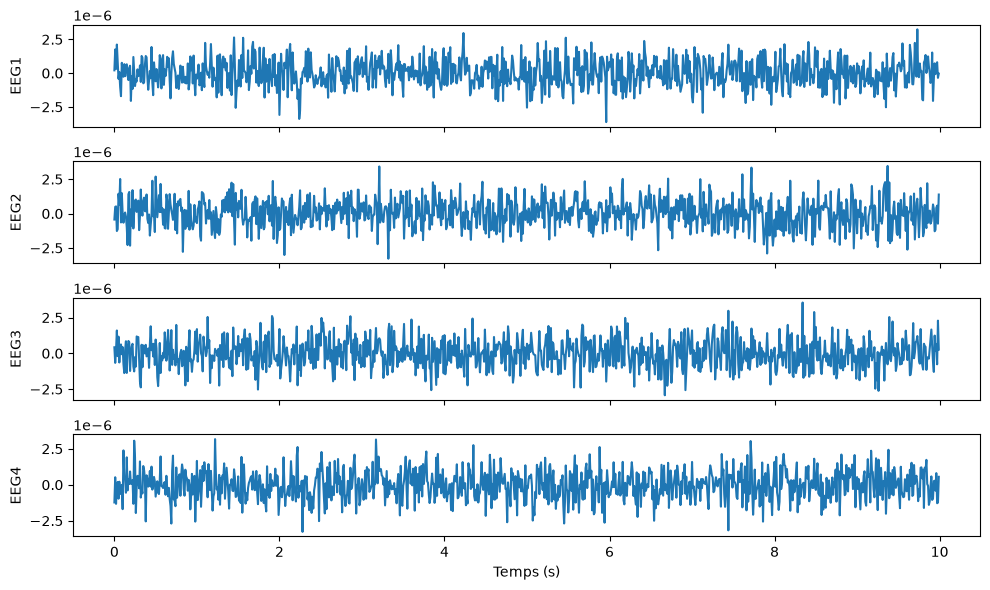

In [6]:
import matplotlib.pyplot as plt
raw = mne.io.read_raw_fif('data/MD5E-s16956--06c9b1cdf4d616c66f2de8d8d33ff867.fif', preload=True, verbose=False)
data, times = raw.get_data(return_times=True)
fig, axes = plt.subplots(len(raw.ch_names), 1, sharex=True, figsize=(10, 6))
for ax, sig, name in zip(axes, data, raw.ch_names):
    ax.plot(times, sig)
    ax.set_ylabel(name)
axes[-1].set_xlabel('Temps (s)')
plt.tight_layout()
plt.show()